# Лабораторная работа 2. Построение baseline-модели: от выбора парадигмы к метрикам качества

**Курс:** Машинное обучение. Безопасность ИИ-систем

**Формат:** индивидуально

**Среда:** Python, scikit-learn, PyTorch

**По материалам Лекции 2.1 и Лекции 2.2**

## Цель работы
Научиться выбирать тип задачи, датасет, baseline-модель и метрики качества, а также сопоставлять структуру данных с соответствующей архитектурой или классическим алгоритмом.

## Результаты обучения
После выполнения работы вы должны уметь:
- различать парадигмы обучения (supervised / unsupervised / reinforcement learning);
- выбирать модель под тип данных и задачу;
- строить baseline для классификации или регрессии;
- выбирать и интерпретировать метрики качества (accuracy, precision, recall, F1, MSE, RMSE, R²);
- сравнивать несколько моделей и делать обоснованный вывод о лучшем baseline.

## Как пользоваться этим ноутбуком
- Ячейки с `# TODO` необходимо заполнить самостоятельно.
- Ячейки с текстом **"Вопрос для отчёта"** требуют письменного ответа в markdown-ячейке ниже.
- Перед сдачей: Kernel → Restart & Run All, ноутбук должен выполняться от начала до конца без ошибок.


## 0. Подготовка окружения

In [ ]:
# TODO: импортируйте необходимые библиотеки
# Подсказка: numpy, pandas, matplotlib, sklearn.*

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, confusion_matrix,
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# TODO: зафиксируйте random_state для воспроизводимости
RANDOM_STATE = 42


## 1. Постановка задачи

**Задание:** выберите один датасет из списка (или согласуйте свой с преподавателем) и определите тип задачи.

Варианты:
- **fetch_20newsgroups** — многоклассовая классификация;
- **diabetes** — регрессия.
- **MNIST** — классификация изображений, простая MLP-модель.

**Вопрос для отчёта:** к какой парадигме обучения относится ваша задача (supervised / unsupervised / reinforcement learning) и почему? Какой тип задачи вы решаете — классификация или регрессия?


_Ваш ответ:_ Я выбрал MNIST, задача многоклассовой классификации с supervised парадигмой (есть целевая переменная с указанием класса (в нашем случае это какая цифра))

## 2. Загрузка и разведочный анализ данных (EDA)

In [ ]:
print("Загрузка датасета MNIST...")
mnist = fetch_openml('mnist_784', version=1, as_frame=True, parser='auto')

# Разделяем на признаки (пиксели) и целевую переменную (цифры)
X = mnist.data  # DataFrame с 784 признаками (пикселями) для каждого фото
y = mnist.target.to_frame(name='target')
df = pd.concat([X, y], axis=1)
df.head()

Загрузка датасета MNIST...


,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784,target
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9


In [ ]:
# TODO: проведите разведочный анализ данных
# - размер выборки (df.shape)
# - типы признаков и целевая переменная (df.dtypes)
# - наличие пропусков (df.isna().sum())
# - баланс классов для классификации (df[target].value_counts())
# - базовые статистики (df.describe())

print("=== Размер выборки ===")
print(f"Формат (строк, колонок): {df.shape}")
print(f"Где строк: {df.shape[0]} (изображений), колонок признаков: {df.shape[1] - 1} (пикселей) + 1 целевая переменная.\n")

print("=== Типы признаков ===")
print(df[[df.columns[0], df.columns[1], df.columns[2], 'target']].dtypes)
print("\n")

print("=== Проверка на наличие пропусков ===")
total_missing = df.isna().sum().sum()
print(f"Общее количество пропущенных значений в датасете: {total_missing}")
if total_missing == 0:
    print("Пропуски отсутствуют, предобработка пустых значений не требуется.\n")
else:
    print("Обнаружены пропуски. Требуется заполнение или удаление.\n")

print("=== Баланс классов ===")
class_counts = df['target'].value_counts().sort_index()
print(class_counts)

print("=== Базовые статистики (только для 5 пикселей) ===")
print(df.iloc[:, 150:155].describe())



=== Размер выборки ===
Формат (строк, колонок): (70000, 785)
Где строк: 70000 (изображений), колонок признаков: 784 (пикселей) + 1 целевая переменная.

=== Типы признаков ===
pixel1       int64
pixel2       int64
pixel3       int64
target    category
dtype: object


=== Проверка на наличие пропусков ===
Общее количество пропущенных значений в датасете: 0
Пропуски отсутствуют, предобработка пустых значений не требуется.

=== Баланс классов ===
target
0    6903
1    7877
2    6990
3    7141
4    6824
5    6313
6    6876
7    7293
8    6825
9    6958
Name: count, dtype: int64
=== Базовые статистики (только для 5 пикселей) ===
           pixel151      pixel152      pixel153      pixel154      pixel155
count  70000.000000  70000.000000  70000.000000  70000.000000  70000.000000
mean      32.020171     44.968157     59.606271     74.405043     85.643914
std       75.070953     86.379065     96.050535    103.363983    107.387809
min        0.000000      0.000000      0.000000      0.000000    

**Вопрос для отчёта:** есть ли в данных пропуски, дисбаланс классов или сильно различающиеся масштабы признаков? Как это повлияет на выбор моделей и предобработки?

_Ваш ответ:_Пропусков нет, дисбаланс около 20% от самого минимального до максимального количества в классе, в целом слабый дисбаланс, все равно лучше смотреть на F1 метрику. Все 784 признкаи представляют собой один формат (тон/яркость пикселя), для моделей чувствительных к масштабу нужна нормализация. Применил мин макс скейлер от 0 до 1.

## 3. Предобработка данных

In [ ]:
# TODO: разделите данные на train/test (train_test_split)
# TODO: при необходимости выполните масштабирование признаков (StandardScaler / MinMaxScaler)
# TODO: при необходимости выполните кодирование категориальных признаков (OneHotEncoder / get_dummies)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Размер обучающей выборки (X_train): {X_train.shape}")
print(f"Размер тестовой выборки (X_test): {X_test.shape}\n")

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Масштабирование завершено. Признаки переведены в диапазон [0, 1].")

Размер обучающей выборки (X_train): (56000, 784)
Размер тестовой выборки (X_test): (14000, 784)

Масштабирование завершено. Признаки переведены в диапазон [0, 1].


## 4. Обучение моделей

**Задание:** обучите не менее **трёх** моделей из списка (минимум одну классическую и минимум одну альтернативную):
- логистическая / линейная регрессия;
- дерево решений;
- k-NN;
- простой MLP.


In [ ]:
print("=== Обучение модели 1: Логистическая регрессия ===")
log_reg = LogisticRegression(solver='saga', max_iter=20, random_state=RANDOM_STATE)

start_time = time.time()
log_reg.fit(X_train_scaled, y_train.values.ravel())
end_time = time.time()

print(f"Модель Логистической регрессии успешно обучена!")
print(f"Время обучения: {end_time - start_time:.2f} секунд.\n")

=== Обучение модели 1: Логистическая регрессия ===
Модель Логистической регрессии успешно обучена!
Время обучения: 47.44 секунд.



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [ ]:
print("=== Обучение модели 2: Дерево решений ===")
tree_clf = DecisionTreeClassifier(max_depth=15, random_state=RANDOM_STATE)

start_time = time.time()
tree_clf.fit(X_train_scaled, y_train.values.ravel())
end_time = time.time()

print(f"Модель Дерева решений успешно обучена!")
print(f"Время обучения: {end_time - start_time:.2f} секунд.\n")

=== Обучение модели 2: Дерево решений ===
Модель Дерева решений успешно обучена!
Время обучения: 17.99 секунд.



In [ ]:
print("=== Обучение модели 3: Простой MLP (Нейросеть) ===")
mlp_clf = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    max_iter=15,
    random_state=RANDOM_STATE,
    verbose=True)

start_time = time.time()
mlp_clf.fit(X_train_scaled, y_train.values.ravel())
end_time = time.time()

print(f"\nМодель MLP успешно обучена!")
print(f"Время обучения: {end_time - start_time:.2f} секунд.\n")

=== Обучение модели 3: Простой MLP (Нейросеть) ===
Iteration 1, loss = 0.45555529
Iteration 2, loss = 0.21853646
Iteration 3, loss = 0.16585916
Iteration 4, loss = 0.13424933
Iteration 5, loss = 0.11123051
Iteration 6, loss = 0.09545541
Iteration 7, loss = 0.08113951
Iteration 8, loss = 0.07240789
Iteration 9, loss = 0.06226367
Iteration 10, loss = 0.05516903
Iteration 11, loss = 0.04909044
Iteration 12, loss = 0.04338635
Iteration 13, loss = 0.03855405
Iteration 14, loss = 0.03419513
Iteration 15, loss = 0.03034622

Модель MLP успешно обучена!
Время обучения: 58.22 секунд.



/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Выбор и расчёт метрик качества

Для классификации используйте минимум **две** метрики из: accuracy, precision, recall, F1, confusion matrix.
Для регрессии используйте минимум **две** метрики из: MSE, RMSE, R².


In [ ]:
models = {
    "Logistic Regression": log_reg,
    "Decision Tree": tree_clf,
    "Simple MLP": mlp_clf,
}

cls_rows = []
reg_rows = []

y_test_int = np.asarray(y_test).ravel().astype(int)

for name, model in models.items():
    # --- Предсказания ---
    y_pred = model.predict(X_test_scaled)
    y_pred_int = np.asarray(y_pred).astype(int)

    # --- Метрики классификации ---
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='weighted')

    cls_rows.append({
        "model": name,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1_score": f1
    })

results_cls = pd.DataFrame(cls_rows)

print("=== МЕТРИКИ КЛАССИФИКАЦИИ ===")
print(results_cls.to_string(index=False))
print("\n" + "=" * 50 + "\n")

=== МЕТРИКИ КЛАССИФИКАЦИИ ===
              model  accuracy  precision   recall  f1_score
Logistic Regression  0.922143   0.921880 0.922143  0.921926
      Decision Tree  0.881357   0.881089 0.881357  0.881155
         Simple MLP  0.974929   0.974953 0.974929  0.974923




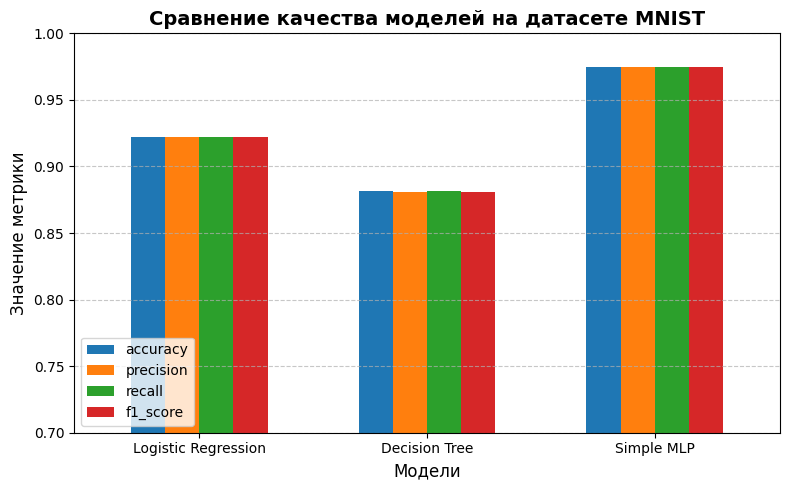

In [ ]:
# TODO: постройте минимум одну визуализацию:
# - confusion matrix, или
# - важность признаков (feature_importances_), или
# - график сравнения метрик по моделям, или
# - дерево решений (plot_tree), или
# - learning curve

df_plot = results_cls.set_index('model')

ax = df_plot.plot(kind='bar', figsize=(8, 5), width=0.6)

plt.title('Сравнение качества моделей на датасете MNIST', fontsize=14, fontweight='bold')
plt.xlabel('Модели', fontsize=12)
plt.ylabel('Значение метрики', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0.7, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower left')

plt.tight_layout()
plt.show()

**Вопрос для отчёта:** почему вы выбрали именно эти метрики? В каких случаях accuracy может вводить в заблуждение (например, при дисбалансе классов)?

_Ваш ответ:_Я выбрал метрики:
 1) accuracy (доля верных ответов),
 2) precision (из тех кого назвали к классу сколько реально в этом классе),
 3) recall (из всех реально классов сколько мы нашли)
 4) F1 для всех моделей (комбинация precision и recall)

 Данные метрики позволяют оценить точность работы модели в роли классификатора, работая с матрицей истинных и предсказанных меток (confusion matrix).
 Accuracy может вводить в заблуждение, если будет сильный дисбаланс классов (много точных предсказаний больших классов -> большой вклад в долю верных ответов -> большая accuracy).

## 6. Анализ ошибок

=== ВЫБОР ЛУЧШЕЙ МОДЕЛИ ПО СУММАРНЫМ МЕТРИКАМ ===
              model  accuracy  precision   recall  f1_score  total_score
Logistic Regression  0.922143   0.921880 0.922143  0.921926     3.688092
      Decision Tree  0.881357   0.881089 0.881357  0.881155     3.524958
         Simple MLP  0.974929   0.974953 0.974929  0.974923     3.899733

 Лучшая модель: Simple MLP (total_score = 3.8997)

=== АНАЛИЗ СИСТЕМАТИЧЕСКИХ ОШИБОК (Simple MLP) ===
Топ-5 самые частые ошибки:
 - '4' → ошибочно как '9': 19 раз
 - '3' → ошибочно как '5': 18 раз
 - '7' → ошибочно как '9': 12 раз
 - '9' → ошибочно как '3': 11 раз
 - '2' → ошибочно как '8': 11 раз


=== ВИЗУАЛИЗАЦИЯ ОШИБОЧНЫХ ИЗОБРАЖЕНИЙ ===
Всего ошибок: 351 из 14000 (2.51%)


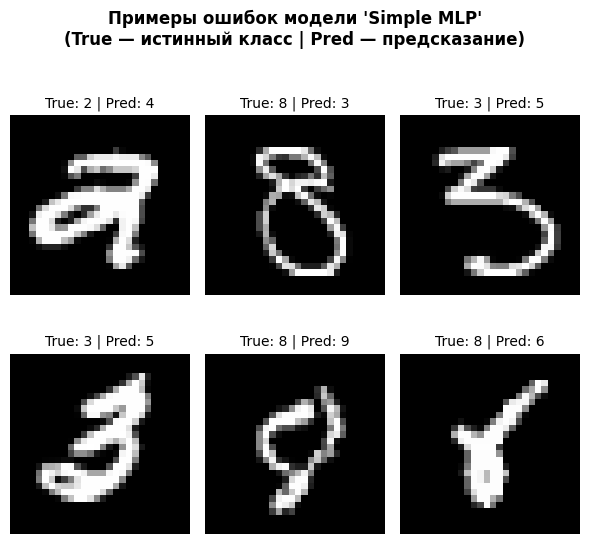

In [ ]:
# TODO: проанализируйте ошибки лучшей модели
# - какие объекты классифицируются неверно?
# - есть ли систематическая ошибка (например, путаница конкретных двух классов)?

# Берём все числовые столбцы метрик и суммируем по строке.
# Чем больше сумма — тем лучше модель по совокупности метрик.
metric_cols = ["accuracy", "precision", "recall", "f1_score"]
results_cls["total_score"] = results_cls[metric_cols].sum(axis=1)
best_row = results_cls.loc[results_cls["total_score"].idxmax()]
best_model_name = best_row["model"]

print("=== ВЫБОР ЛУЧШЕЙ МОДЕЛИ ПО СУММАРНЫМ МЕТРИКАМ ===")
print(results_cls.to_string(index=False))
print(f"\n Лучшая модель: {best_model_name} "
      f"(total_score = {best_row['total_score']:.4f})\n")

best_model = models[best_model_name]

print(f"=== АНАЛИЗ СИСТЕМАТИЧЕСКИХ ОШИБОК ({best_model_name}) ===")

y_pred_best = np.asarray(best_model.predict(X_test_scaled)).astype(int)
y_test_arr = np.asarray(y_test).ravel().astype(int)

# Матрица ошибок 10×10. cm[i, j] = сколько объектов истинного класса i
# модель отнесла к классу j (диагональ — правильные ответы).
cm = confusion_matrix(y_test_arr, y_pred_best)

# Обнуляем диагональ — оставляем только ошибки.
cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

# Индексы 100 ячеек, отсортированные по убыванию числа ошибок.
flat_indices = np.argsort(cm_errors.flatten())[::-1]

print("Топ-5 самые частые ошибки:")
for i in range(5):
    idx = flat_indices[i]
    true_class = idx // 10    # номер строки = истинный класс
    pred_class = idx % 10     # номер столбца = предсказанный класс
    count = cm_errors[true_class, pred_class]
    if count == 0:
        break
    print(f" - '{true_class}' → ошибочно как '{pred_class}': {count} раз")
print("\n" + "=" * 50 + "\n")


print("=== ВИЗУАЛИЗАЦИЯ ОШИБОЧНЫХ ИЗОБРАЖЕНИЙ ===")

# Все позиции, где модель ошиблась
misclassified_indices = np.where(y_test_arr != y_pred_best)[0]
print(f"Всего ошибок: {len(misclassified_indices)} "
      f"из {len(y_test_arr)} ({100*len(misclassified_indices)/len(y_test_arr):.2f}%)")

rng = np.random.default_rng(RANDOM_STATE)
n_show = min(6, len(misclassified_indices))
sample_idx = rng.choice(misclassified_indices, size=n_show, replace=False)

X_test_arr = np.asarray(X_test)

fig, axes = plt.subplots(2, 3, figsize=(6, 6))
fig.suptitle(f"Примеры ошибок модели '{best_model_name}'\n"
             f"(True — истинный класс | Pred — предсказание)",
             fontsize=12, fontweight='bold')

for ax, idx in zip(axes.ravel(), sample_idx):
    image = X_test_arr[idx].reshape(28, 28)
    ax.imshow(image, cmap='gray')
    ax.set_title(f"True: {y_test_arr[idx]} | Pred: {y_pred_best[idx]}", fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()


## 7. Сравнение моделей и вывод

**Вопрос для отчёта:** какая модель показала лучший результат по выбранным метрикам? Согласуется ли это с ожиданиями, учитывая структуру данных (линейность, размер выборки, число признаков)? Какую модель вы бы выбрали в качестве baseline и почему?

_Ваш ответ:_ Лучшая модель исходя из метрик - MLP, что согласуется с ожиданиями, благодаря архитектурной способности улавливать нелинейные пространственные зависимости, которые есть в MNIST (классификация изображений). Для baseline я бы выбрал MLP, потому что это простейшая модель из целевого семейства и изначально предназначена для классификации изображений.

---
Выполните **не менее двух** из следующих заданий. Оформите результаты в отдельных ячейках ниже

### С1. Кластеризация как альтернативный взгляд на данные
Примените unsupervised-подход (например, KMeans) к тем же признакам без использования целевой переменной. Сравните полученные кластеры с реальными классами/значениями целевой переменной. Обсудите: совпадает ли структура кластеров с реальной разметкой? Что это говорит о структуре данных?

### С2. Классический baseline vs простой MLP
Обучите простую нейросеть (MLPClassifier/MLPRegressor из sklearn, либо небольшую сеть на PyTorch) на тех же признаках и сравните её с лучшей классической моделью по тем же метрикам. Объясните, почему нейросеть выигрывает/проигрывает при данном объёме данных и числе признаков.

### С3. Устойчивость вывода о «лучшей» модели к выбору метрики
Постройте искусственный дисбаланс классов (например, undersampling одного класса) и пересчитайте метрики для всех моделей. Проверьте: меняется ли ранжирование моделей при использовании accuracy против F1/recall? Сделайте вывод о том, почему выбор метрики критичен при дисбалансе.

### С4. Кросс-валидация и доверительный интервал качества
Замените единичный train/test split на k-fold кросс-валидацию (cross_val_score) для всех моделей. Постройте boxplot распределения метрики по фолдам. Обсудите, насколько стабильны результаты моделей.


=== ЗАДАНИЕ C1: КЛАСТЕРИЗАЦИЯ KMeans ===

Матрица сопряжённости (реальные цифры × кластеры):
Кластер          0    1    2    3    4    5    6   7   8   9
Реальная цифра                                              
0                7    7    4    1    7    0    0  86   2  84
1                0    1    1  107    1    0  114   0   0   0
2                5   14  147   17    5    1    7   3   9   0
3               39  126   11   19    1    0    0   6   3   0
4                0    0    2    7    6   59    6   0  99   0
5               76   65    0   13    4    9    6   5  14   0
6                7    1    1   17  146    0    1   8   6   2
7                0    1    4   13    0  104    5   1  88   0
8               97   61    1   19    1   12    3   1   5   0
9                1    4    2   11    1   81    2   1  85   1

Purity кластеров: 0.540
(1.0 = кластеры идеально совпадают с классами, 0.1 = случайно)



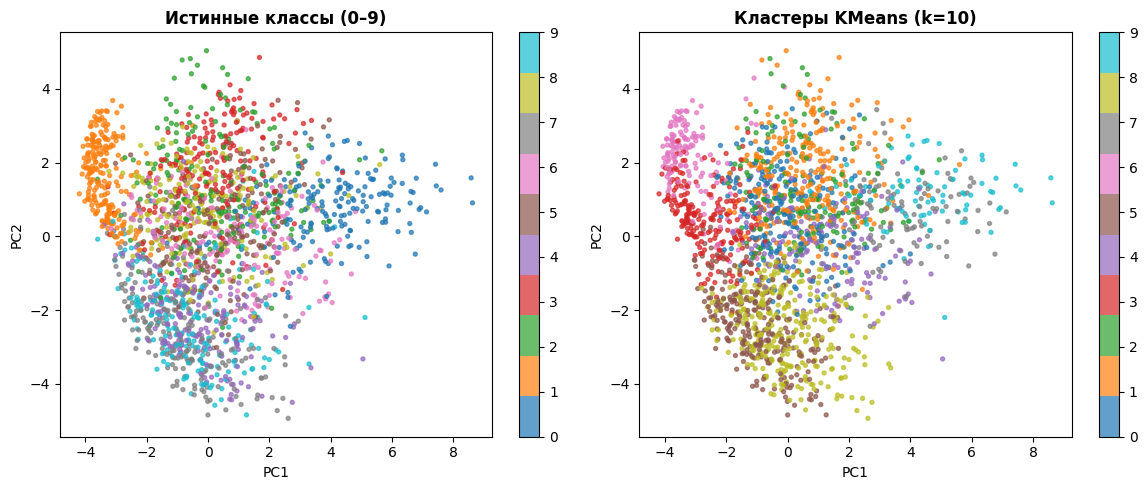

In [ ]:
# TODO: реализуйте выбранные задания (С1-С4) здесь

print("=== ЗАДАНИЕ C1: КЛАСТЕРИЗАЦИЯ KMeans ===")

# --- 1. Подготовка подвыборки ---
N_SUB = 2000
X_sub = X_train_scaled[:N_SUB]
y_sub = y_train.values.ravel()[:N_SUB].astype(int)

# --- 2. Обучение KMeans ---
# k=10, потому что цифр ровно 10. random_state для воспроизводимости,
# n_init=10 — 10 разных инициализаций, выбираем лучшую (уменьшает шанс
# попасть в локальный минимум).
kmeans = KMeans(n_clusters=10, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_sub)

# --- 3. Матрица сопряжённости: реальный класс × номер кластера ---
contingency = pd.crosstab(
    index=y_sub,
    columns=cluster_labels,
    rownames=['Реальная цифра'],
    colnames=['Кластер']
)

print("\nМатрица сопряжённости (реальные цифры × кластеры):")
print(contingency)
print()

# --- 4. Метрика «чистоты» кластеров (purity) ---
# Показывает, какую долю объектов можно «правильно» разметить,
# если каждому кластеру приписать его класс.
def purity_score(y_true, y_pred):
    cm = pd.crosstab(y_true, y_pred)
    return cm.max(axis=1).sum() / cm.values.sum()

purity = purity_score(y_sub, cluster_labels)
print(f"Purity кластеров: {purity:.3f}")
print("(1.0 = кластеры идеально совпадают с классами, 0.1 = случайно)\n")

# --- 5. Визуализация кластеров через PCA (2D) ---
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X_sub)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

scatter1 = axes[0].scatter(X_2d[:, 0], X_2d[:, 1],
                           c=y_sub, cmap='tab10', s=8, alpha=0.7)
axes[0].set_title("Истинные классы (0–9)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
plt.colorbar(scatter1, ax=axes[0], ticks=range(10))

scatter2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1],
                           c=cluster_labels, cmap='tab10', s=8, alpha=0.7)
axes[1].set_title("Кластеры KMeans (k=10)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
plt.colorbar(scatter2, ax=axes[1], ticks=range(10))

plt.tight_layout()
plt.show()


Только 54% данных совпдают по структуре с кластерами. Это трактуется тем, что даже одинаковые цифры могут значительно отличаться в написании, и наоборот разные цифры могут быть очень похожими.

=== ЗАДАНИЕ C2: MLP vs КЛАССИЧЕСКИЕ МОДЕЛИ ===

Лучшая классическая модель: Logistic Regression
  accuracy = 0.9221, F1 = 0.9219
MLP:
  accuracy = 0.9749, F1 = 0.9749

Разница (MLP − Logistic Regression):
  Δ accuracy = +0.0528 (+5.28 п.п.)
  Δ F1       = +0.0530 (+5.30 п.п.)

Сравнение бок-о-бок:
              model  accuracy  precision   recall  f1_score
Logistic Regression  0.922143   0.921880 0.922143  0.921926
         Simple MLP  0.974929   0.974953 0.974929  0.974923


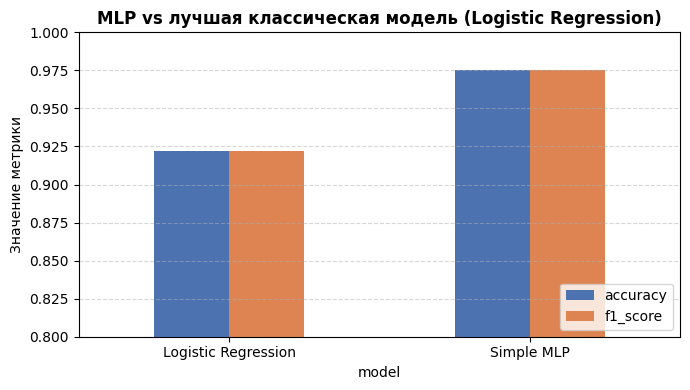

In [ ]:
print("=== ЗАДАНИЕ C2: MLP vs КЛАССИЧЕСКИЕ МОДЕЛИ ===\n")

classical_models = ["Logistic Regression", "Decision Tree"]

best_classical_row = (results_cls[results_cls["model"].isin(classical_models)]
                      .sort_values("accuracy", ascending=False)
                      .iloc[0])
best_classical_name = best_classical_row["model"]

mlp_row = results_cls[results_cls["model"] == "Simple MLP"].iloc[0]

print(f"Лучшая классическая модель: {best_classical_name}")
print(f"  accuracy = {best_classical_row['accuracy']:.4f}, "
      f"F1 = {best_classical_row['f1_score']:.4f}")
print(f"MLP:")
print(f"  accuracy = {mlp_row['accuracy']:.4f}, "
      f"F1 = {mlp_row['f1_score']:.4f}")

delta_acc = mlp_row["accuracy"] - best_classical_row["accuracy"]
delta_f1  = mlp_row["f1_score"] - best_classical_row["f1_score"]

print(f"\nРазница (MLP − {best_classical_name}):")
print(f"  Δ accuracy = {delta_acc:+.4f} ({delta_acc*100:+.2f} п.п.)")
print(f"  Δ F1       = {delta_f1:+.4f} ({delta_f1*100:+.2f} п.п.)")

comparison = results_cls[results_cls["model"].isin(
    [best_classical_name, "Simple MLP"]
)][["model", "accuracy", "precision", "recall", "f1_score"]]
print("\nСравнение бок-о-бок:")
print(comparison.to_string(index=False))

comparison_plot = comparison.set_index("model")[["accuracy", "f1_score"]]
comparison_plot.plot(kind='bar', figsize=(7, 4), color=['#4C72B0', '#DD8452'])
plt.title(f'MLP vs лучшая классическая модель ({best_classical_name})',
          fontsize=12, fontweight='bold')
plt.ylabel('Значение метрики')
plt.ylim(0.8, 1.0)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Благодаря тому, что задача подразумевает классификацию на основе нелинейной пространственной комбинации пикселей, MLP выигрывает ожидаемо. Логистическая регрессия даёт 92% не по случайности, а потому что MNIST в высокой размерности почти линейно разделим, а пиксели - полезные и характерные признаки.

---



## Требования к сдаче
- Ноутбук выполняется целиком без ошибок (Kernel → Restart & Run All).
- Все `# TODO` заполнены, все вопросы для отчёта содержат письменный ответ.
- Минимум 3 модели, минимум 2 метрики, минимум 1 визуализация.
